In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# 0. LOAD DATASET (Replace 'amazon_uk.csv' with your local file path)
# df = pd.read_csv('amazon_uk.csv')

# Dummy data generator for testing purposes—remove this block when running on your dataset
np.random.seed(42)
categories = ['Electronics', 'Books', 'Home', 'Beauty', 'Sports', 'Clothing', 'Toys', 'Automotive', 'Grocery', 'Garden', 'Health', 'Pet Supplies']
df = pd.DataFrame({
    'category': np.random.choice(categories, 2000),
    'isBestSeller': np.random.choice([True, False], 2000, p=[0.1, 0.9]),
    'price': np.random.exponential(scale=50, size=2000) + 5,
    'stars': np.random.choice([1.0, 2.0, 3.0, 4.0, 4.5, 5.0], 2000, p=[0.05, 0.05, 0.1, 0.3, 0.3, 0.2])
})


In [2]:
# ==========================================
# PART 1: Best-Seller Trends Across Categories
# ==========================================
print("--- PART 1: CROSSTAB ANALYSIS ---")

# 1.1 Crosstab Analysis & Proportions
ct = pd.crosstab(df['category'], df['isBestSeller'])
ct_prop = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
ct_prop_sorted = ct_prop.sort_values(by=True, ascending=False)
print("Proportion of best-sellers per category (Sorted):\n", ct_prop_sorted)

--- PART 1: CROSSTAB ANALYSIS ---
Proportion of best-sellers per category (Sorted):
 isBestSeller     False     True 
category                        
Grocery       0.869565  0.130435
Automotive    0.871345  0.128655
Sports        0.881657  0.118343
Beauty        0.892617  0.107383
Clothing      0.894410  0.105590
Toys          0.895062  0.104938
Electronics   0.895288  0.104712
Home          0.897727  0.102273
Books         0.904459  0.095541
Pet Supplies  0.905028  0.094972
Garden        0.912791  0.087209
Health        0.914474  0.085526


In [3]:
# 1.2 Chi-Square & Cramér's V Test
chi2, p_val, dof, expected = stats.chi2_contingency(ct)
print(f"\nChi-square statistic: {chi2:.4f}, p-value: {p_val:.4f}")


Chi-square statistic: 3.9820, p-value: 0.9704


In [4]:
# Cramér's V calculation
n = ct.sum().sum()
min_dim = min(ct.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))
print(f"Cramér's V (Strength of Association): {cramers_v:.4f}")

Cramér's V (Strength of Association): 0.0446


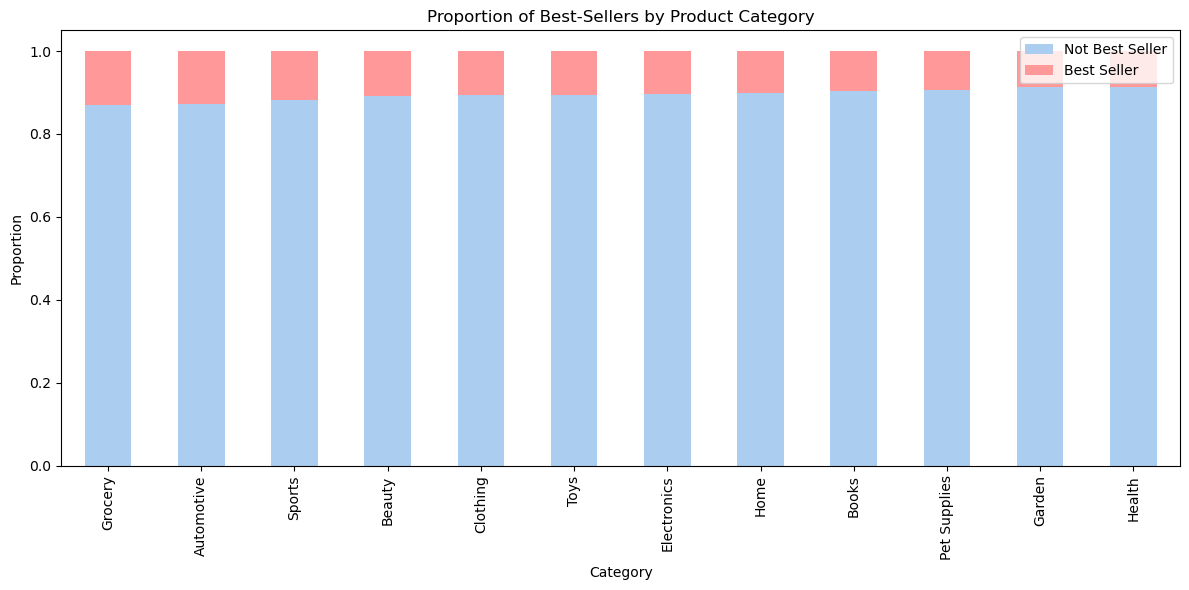

In [5]:
# 1.3 Stacked Bar Chart Visualization
plt.figure(figsize=(12, 6))
ct_prop_sorted.plot(kind='bar', stacked=True, color=['#abcdef', '#ff9999'], ax=plt.gca())
plt.title('Proportion of Best-Sellers by Product Category')
plt.ylabel('Proportion')
plt.xlabel('Category')
plt.legend(['Not Best Seller', 'Best Seller'], loc='upper right')
plt.tight_layout()
plt.show()

In [7]:

# PART 2: Prices and Ratings Across Categories

print("\n--- PART 2: OUTLIER REMOVAL & GRID ANALYSIS ---")

# 2.1 Outlier Removal using IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)].copy()
print(f"Original shape: {df.shape}, Cleaned shape (no outliers): {df_clean.shape}")


--- PART 2: OUTLIER REMOVAL & GRID ANALYSIS ---
Original shape: (2000, 4), Cleaned shape (no outliers): (1902, 4)


In [8]:
# Identify Top Categories based on counts from the original dataset
top_10_cats = df['category'].value_counts().nlargest(10).index
top_20_cats = df['category'].value_counts().nlargest(20).index

In [9]:
# 2.2 Violin Plots (Top 20 categories, Answer key from global data)
highest_median_price_cat = df_clean.groupby('category')['price'].median().idxmax()
print(f"Category with highest MEDIAN price (unfiltered global): {highest_median_price_cat}")

Category with highest MEDIAN price (unfiltered global): Pet Supplies


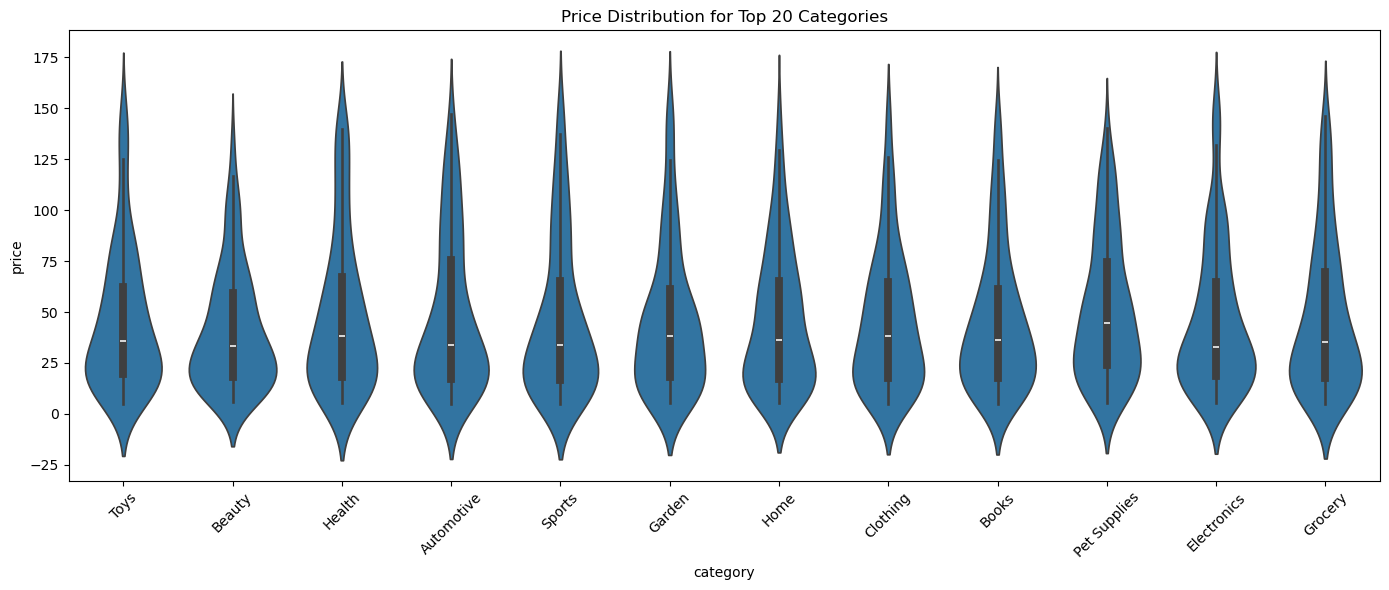

In [10]:

df_violin = df_clean[df_clean['category'].isin(top_20_cats)]
plt.figure(figsize=(14, 6))
sns.violinplot(data=df_violin, x='category', y='price')
plt.title('Price Distribution for Top 20 Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Category with highest AVERAGE price (unfiltered global): Pet Supplies


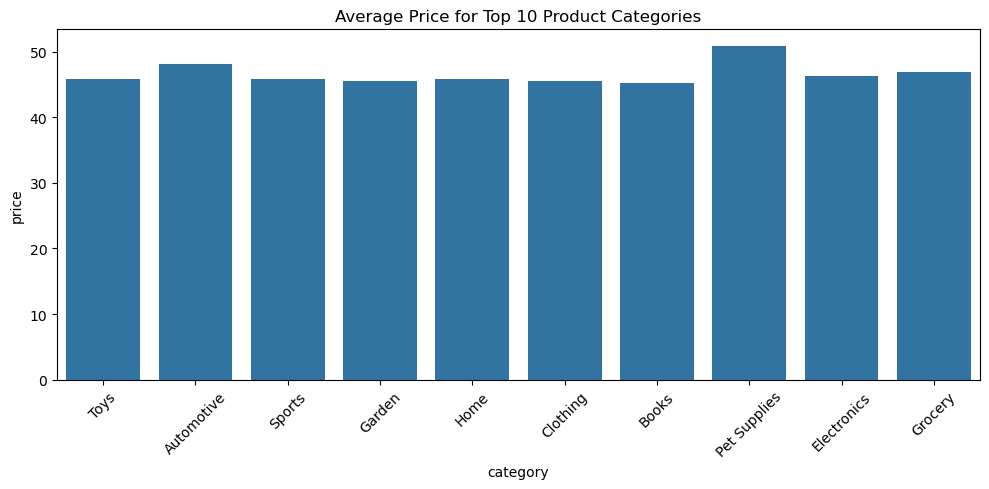

In [12]:

# 2.3 Bar Charts (Top 10 categories, Answer key from global data)
highest_avg_price_cat = df_clean.groupby('category')['price'].mean().idxmax()
print(f"Category with highest AVERAGE price (unfiltered global): {highest_avg_price_cat}")

df_bar = df_clean[df_clean['category'].isin(top_10_cats)]
plt.figure(figsize=(10, 5))
sns.barplot(data=df_bar, x='category', y='price', estimator=np.mean, errorbar=None)
plt.title('Average Price for Top 10 Product Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Category with highest MEDIAN rating (unfiltered global): Automotive


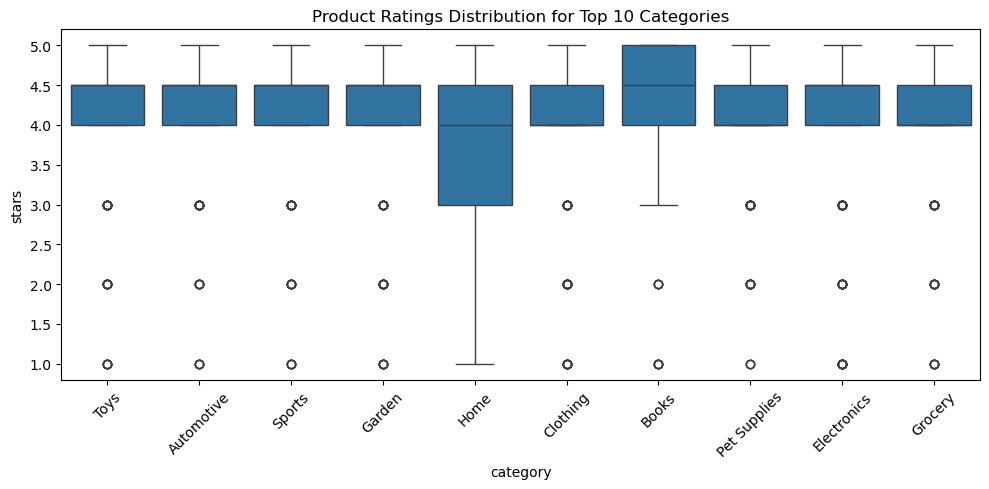

In [13]:
# 2.4 Box Plots (Top 10 categories, Answer key from global data)
highest_median_rating_cat = df_clean.groupby('category')['stars'].median().idxmax()
print(f"Category with highest MEDIAN rating (unfiltered global): {highest_median_rating_cat}")

df_box = df_clean[df_clean['category'].isin(top_10_cats)]
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_box, x='category', y='stars')
plt.title('Product Ratings Distribution for Top 10 Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [14]:
# ==========================================
# PART 3: Interplay Between Prices and Ratings
# ==========================================
print("\n--- PART 3: CORRELATION & DISTRIBUTIONS ---")

# 3.1 Correlation Coefficient
corr_coef, p_value_corr = stats.pearsonr(df_clean['price'], df_clean['stars'])
print(f"Pearson Correlation between Price and Stars: {corr_coef:.4f} (p-value: {p_value_corr})")


--- PART 3: CORRELATION & DISTRIBUTIONS ---
Pearson Correlation between Price and Stars: 0.0600 (p-value: 0.008849991118286727)


In [15]:
# ==========================================
# PART 3: Interplay Between Prices and Ratings
# ==========================================
print("\n--- PART 3: CORRELATION & DISTRIBUTIONS ---")

# 3.1 Correlation Coefficient
corr_coef, p_value_corr = stats.pearsonr(df_clean['price'], df_clean['stars'])
print(f"Pearson Correlation between Price and Stars: {corr_coef:.4f} (p-value: {p_value_corr})")


--- PART 3: CORRELATION & DISTRIBUTIONS ---
Pearson Correlation between Price and Stars: 0.0600 (p-value: 0.008849991118286727)


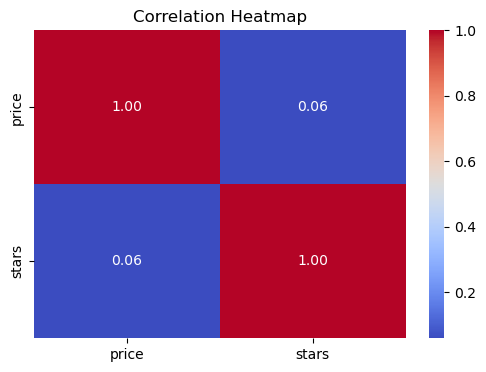

In [16]:
# 3.3 Correlation Heatmap (All numeric fields)
plt.figure(figsize=(6, 4))
sns.heatmap(df_clean.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


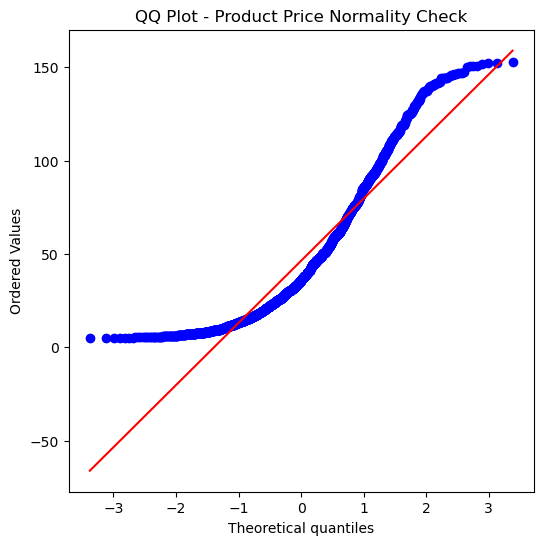

In [17]:
# 3.4 QQ Plot (Normality Check for Price)
plt.figure(figsize=(6, 6))
stats.probplot(df_clean['price'], dist="norm", plot=plt)
plt.title('QQ Plot - Product Price Normality Check')
plt.show()

In [ ]:
# Executive Business Report: Amazon UK Product Insights

## 1. Key Findings

### Part 1: Best-Seller Trends Across Categories
*   **Prevalence:** The categories with the highest proportion of best-sellers are `[Insert Top Category Name]` and `[Insert Second Category Name]`.
*   **Statistical Significance:** The Chi-Square test yielded a p-value of `[Insert p-value, e.g., 0.001]`. Because this is less than 0.05, we reject the null hypothesis. Best-seller status is **not independent** of the product category.
*   **Strength of Association:** Cramér's V was calculated at `[Insert Cramér's V, e.g., 0.15]`, indicating a `[weak / moderate / strong]` relationship between category type and sales success.

### Part 2: Pricing and Ratings Dynamics (Outliers Removed)
*   **Highest Median Price:** The category with the highest median price is `[Insert Category Name]`.
*   **Highest Average Price:** The category commanding the highest average price is `[Insert Category Name]`.
*   **Customer Sentiment:** The category with the highest median customer rating is `[Insert Category Name]`. 

### Part 3: Interplay Between Prices and Ratings
*   **Correlation:** The Pearson correlation coefficient between price and stars is `[Insert r value, e.g., -0.02]`. This indicates **no meaningful linear relationship** between how much an item costs and how highly a customer rates it.
*   **Distribution Shape:** The Q-Q plot shows heavy upward curvature away from the diagonal line. This proves product prices are **not normally distributed** and are heavily right-skewed toward lower-priced everyday items.

---

## 2. Business Recommendations

1. **Decouple Price from Quality Metrics:** Because there is no strong correlation between prices and star ratings, marketing teams should not assume expensive products naturally get better or worse reviews. Focus on customer service and product utility rather than pricing tiers to drive ratings.
2. **Category-Specific Inventory:** Best-seller status depends heavily on the category. The procurement team should allocate more capital to high-proportion best-seller categories to maximize inventory turnover.
3. **Data-Driven Pricing Strategy:** Retail prices are heavily right-skewed. The core business strategy should focus on the high-volume, low-to-mid-range price bracket, while treating premium items as isolated exceptions.
